# Project Cupid
## An End-to-End Machine Learning Pipeline for Relationship Compatibility & Longevity Prediction

**Capstone project | Python, Pandas, NumPy, Matplotlib, Seaborn, Scikit-learn**

### Important dataset note
The supplied project brief does not include a raw dataset. This notebook therefore creates a **synthetic demonstration dataset** so that the full pipeline can be executed and tested. The data and scores are illustrative only; they do not establish real-world relationship compatibility. Replace the synthetic data with the faculty-provided dataset if it becomes available.

### Project objectives
1. **Classification:** predict `Relationship_Success` (0 or 1).
2. **Regression:** predict `Compatibility_Score` (10–100).

The notebook follows the five modules in the project brief.

## Setup — install/import libraries

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (
    train_test_split, StratifiedKFold, KFold,
    cross_validate, RandomizedSearchCV
)
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.feature_selection import SelectFromModel
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor
from sklearn.ensemble import (
    RandomForestClassifier, AdaBoostClassifier,
    RandomForestRegressor, AdaBoostRegressor
)
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, classification_report, confusion_matrix,
    mean_absolute_error, mean_squared_error, r2_score
)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
print("Libraries imported successfully.")

Libraries imported successfully.


## Module 1 — Data Exploration, Wrangling, and Cleaning

Because the official dataset was not supplied, this cell creates a synthetic dataset with plausible columns, missing values, categorical zodiac signs, and deliberately unrealistic income typos. The targets are generated from simulated patterns so we can test the modelling workflow.

In [2]:
n = 1200
rng = np.random.default_rng(RANDOM_STATE)

age = rng.integers(18, 61, size=n)
income = rng.lognormal(mean=np.log(45000), sigma=0.55, size=n).clip(12000, 250000)
communication = rng.integers(1, 11, size=n)
trust = rng.integers(1, 11, size=n)
shared_values = rng.integers(1, 11, size=n)
conflict_resolution = rng.integers(1, 11, size=n)
red_flags = rng.integers(0, 6, size=n)
zodiac = rng.choice(
    ["Aries", "Taurus", "Gemini", "Cancer", "Leo", "Virgo",
     "Libra", "Scorpio", "Sagittarius", "Capricorn", "Aquarius", "Pisces"],
    size=n
)

# Composite signal used only to create illustrative synthetic target labels.
relationship_signal = (
    0.27 * communication + 0.28 * trust +
    0.25 * shared_values + 0.25 * conflict_resolution -
    0.75 * red_flags
)
prob_success = 1 / (1 + np.exp(-(relationship_signal - 5.8)))
relationship_success = rng.binomial(1, prob_success)
compatibility_score = (
    10 + 9.2 * communication + 9.8 * trust +
    9.0 * shared_values + 9.4 * conflict_resolution -
    5.2 * red_flags + rng.normal(0, 8, n)
)
compatibility_score = np.clip(compatibility_score, 10, 100).round(1)

df = pd.DataFrame({
    "Age": age,
    "Monthly_Income": income.round(2),
    "Communication_Score": communication,
    "Trust_Score": trust,
    "Shared_Values_Score": shared_values,
    "Conflict_Resolution_Score": conflict_resolution,
    "Red_Flags": red_flags,
    "Zodiac_Sign": zodiac,
    "Relationship_Success": relationship_success,
    "Compatibility_Score": compatibility_score
})

# Insert deliberate data-quality issues for practice.
income_typo_rows = rng.choice(df.index, size=8, replace=False)
df.loc[income_typo_rows, "Monthly_Income"] = rng.choice(
    [1_000_000, 5_000_000, 10_000_000], size=len(income_typo_rows)
)

for col in ["Monthly_Income", "Communication_Score", "Trust_Score",
            "Zodiac_Sign", "Shared_Values_Score"]:
    missing_idx = rng.choice(df.index, size=int(0.04 * n), replace=False)
    df.loc[missing_idx, col] = np.nan

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (1200, 10)


,Age,Monthly_Income,Communication_Score,Trust_Score,Shared_Values_Score,Conflict_Resolution_Score,Red_Flags,Zodiac_Sign,Relationship_Success,Compatibility_Score
0,21,89392.34,10.0,8.0,6.0,8,4,Virgo,1,100.0
1,51,39164.78,6.0,8.0,5.0,5,2,Scorpio,0,100.0
2,46,54957.62,7.0,9.0,2.0,2,2,NaN,1,100.0
3,36,10000000.00,7.0,1.0,6.0,9,0,Sagittarius,0,100.0
4,36,23823.47,10.0,2.0,2.0,5,4,Pisces,0,100.0


In [3]:
print("Data types:")
display(df.dtypes.to_frame("Data_Type"))

print("Missing values per column:")
display(df.isna().sum().to_frame("Missing_Count"))

print("Numeric summary:")
display(df.describe().T)

Data types:


,Data_Type
Age,int64
Monthly_Income,float64
Communication_Score,float64
Trust_Score,float64
Shared_Values_Score,float64
Conflict_Resolution_Score,int64
Red_Flags,int64
Zodiac_Sign,object
Relationship_Success,int64
Compatibility_Score,float64


Missing values per column:


,Missing_Count
Age,0
Monthly_Income,48
Communication_Score,48
Trust_Score,48
Shared_Values_Score,48
Conflict_Resolution_Score,0
Red_Flags,0
Zodiac_Sign,48
Relationship_Success,0
Compatibility_Score,0


Numeric summary:


,count,mean,std,min,25%,50%,75%,max
Age,1200.0,39.180000,12.363453,18.0,28.0000,39.000,50.0000,60.0
Monthly_Income,1152.0,95962.569766,622092.290105,12000.0,30416.1575,44918.995,63620.6875,10000000.0
Communication_Score,1152.0,5.372396,2.894802,1.0,3.0000,5.000,8.0000,10.0
Trust_Score,1152.0,5.563368,2.838144,1.0,3.0000,6.000,8.0000,10.0
Shared_Values_Score,1152.0,5.327257,2.903251,1.0,3.0000,5.000,8.0000,10.0
Conflict_Resolution_Score,1200.0,5.387500,2.819983,1.0,3.0000,5.000,8.0000,10.0
Red_Flags,1200.0,2.536667,1.701784,0.0,1.0000,3.000,4.0000,5.0
Relationship_Success,1200.0,0.213333,0.409832,0.0,0.0000,0.000,0.0000,1.0
Compatibility_Score,1200.0,99.388583,4.282006,43.6,100.0000,100.000,100.0000,100.0


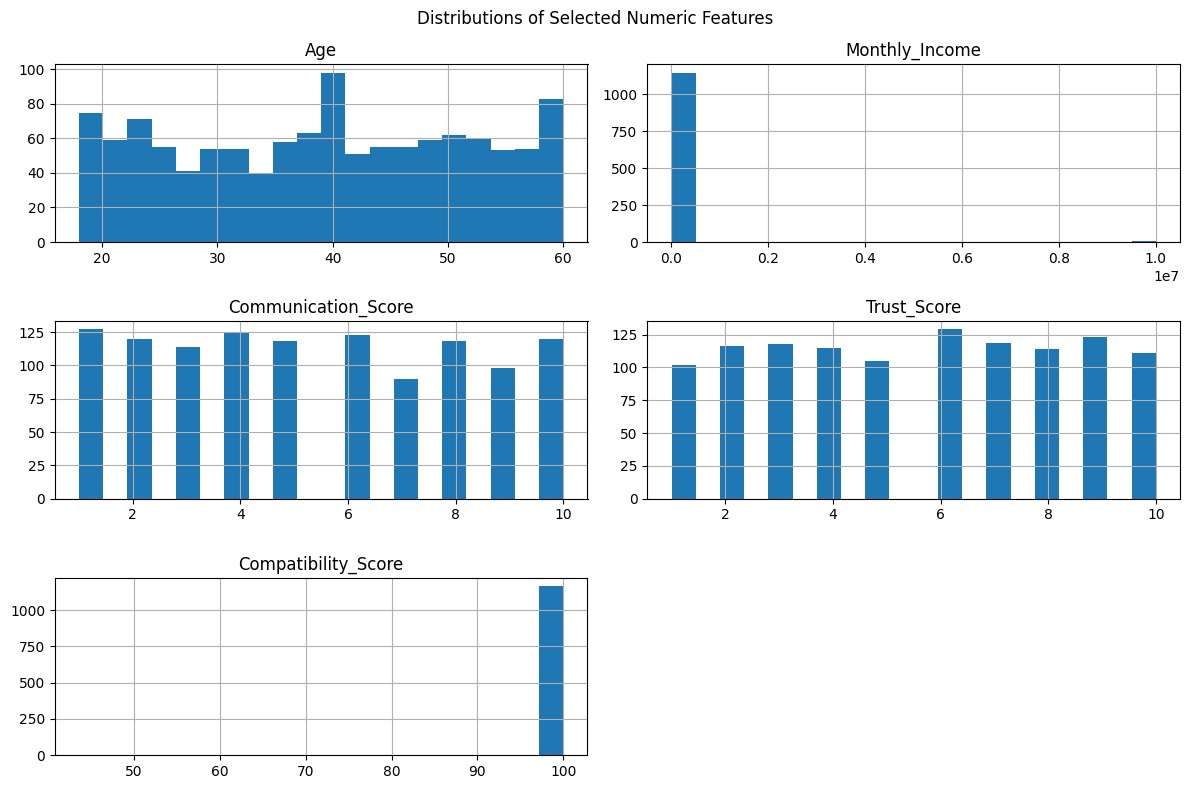

Relationship_Success class proportions:


,proportion
Relationship_Success,
0,0.786667
1,0.213333


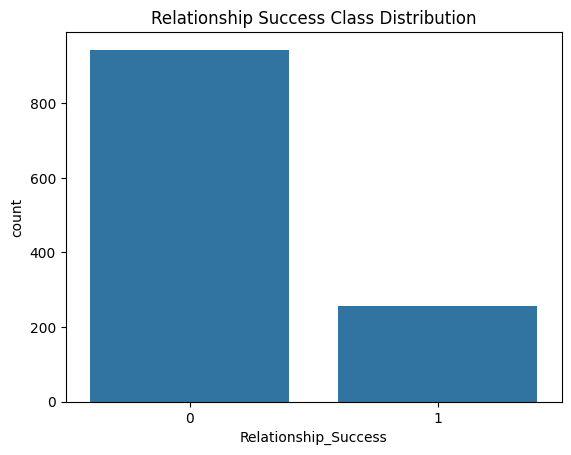

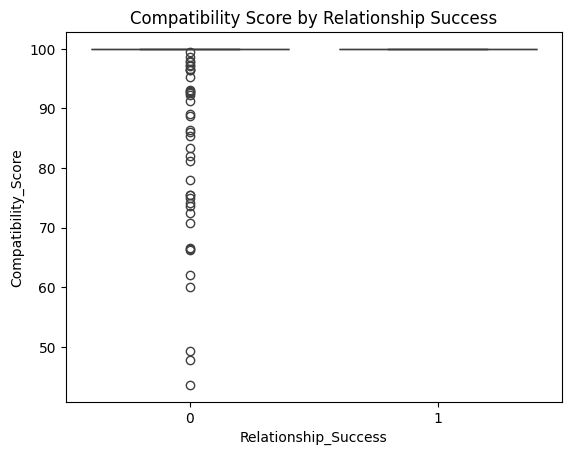

In [4]:
# Univariate exploration
df[["Age", "Monthly_Income", "Communication_Score", "Trust_Score",
    "Compatibility_Score"]].hist(figsize=(12, 8), bins=20)
plt.suptitle("Distributions of Selected Numeric Features")
plt.tight_layout()
plt.show()

# Target balance
print("Relationship_Success class proportions:")
display(df["Relationship_Success"].value_counts(normalize=True).rename("proportion"))

sns.countplot(data=df, x="Relationship_Success")
plt.title("Relationship Success Class Distribution")
plt.show()

# Bivariate check
sns.boxplot(data=df, x="Relationship_Success", y="Compatibility_Score")
plt.title("Compatibility Score by Relationship Success")
plt.show()

### IQR outlier detection and treatment

The IQR rule identifies values below Q1 − 1.5×IQR or above Q3 + 1.5×IQR. Here we inspect monthly income, where the generated dataset deliberately contains extreme typographical errors. To preserve rows, this demonstration caps flagged income values at the upper IQR boundary. In a real project, investigate flagged records first: do not automatically remove legitimate high-income observations.

In [5]:
df_clean = df.copy()

q1 = df_clean["Monthly_Income"].quantile(0.25)
q3 = df_clean["Monthly_Income"].quantile(0.75)
iqr = q3 - q1
lower_bound = max(0, q1 - 1.5 * iqr)
upper_bound = q3 + 1.5 * iqr

outlier_mask = (
    (df_clean["Monthly_Income"] < lower_bound) |
    (df_clean["Monthly_Income"] > upper_bound)
)
print("Income IQR lower bound:", round(lower_bound, 2))
print("Income IQR upper bound:", round(upper_bound, 2))
print("Rows flagged by income IQR rule:", int(outlier_mask.sum()))

before_max = df_clean["Monthly_Income"].max()
df_clean["Monthly_Income"] = df_clean["Monthly_Income"].clip(
    lower=lower_bound, upper=upper_bound
)
print("Income maximum before treatment:", before_max)
print("Income maximum after treatment:", round(df_clean["Monthly_Income"].max(), 2))

Income IQR lower bound: 0
Income IQR upper bound: 113427.48
Rows flagged by income IQR rule: 60
Income maximum before treatment: 10000000.0
Income maximum after treatment: 113427.48


## Module 2 — Feature Engineering, Encoding, and Scaling

Create a composite **Emotional_Intelligence_Index** using communication, trust, and conflict-resolution scores. Missing values are left for the imputation pipeline. One-hot encoding is used for zodiac signs because zodiac categories have no meaningful numeric order. StandardScaler is applied to numeric features inside the modelling pipeline.

In [6]:
df_model = df_clean.copy()
df_model["Emotional_Intelligence_Index"] = df_model[
    ["Communication_Score", "Trust_Score", "Conflict_Resolution_Score"]
].mean(axis=1)

print("New engineered feature added.")
display(df_model[[
    "Communication_Score", "Trust_Score", "Conflict_Resolution_Score",
    "Emotional_Intelligence_Index"
]].head())

New engineered feature added.


,Communication_Score,Trust_Score,Conflict_Resolution_Score,Emotional_Intelligence_Index
0,10.0,8.0,8,8.666667
1,6.0,8.0,5,6.333333
2,7.0,9.0,2,6.000000
3,7.0,1.0,9,5.666667
4,10.0,2.0,5,5.666667


## Module 3 — Feature Selection and Validation Strategy

We separate the two targets and use a held-out test set. The preprocessing steps are placed inside scikit-learn pipelines to avoid fitting imputers, encoders, or scalers on the test data. Classification uses **StratifiedKFold**; regression uses **KFold**. Feature selection uses a tree-based selector within each model pipeline.

In [7]:
target_class = "Relationship_Success"
target_reg = "Compatibility_Score"
feature_cols = [
    "Age", "Monthly_Income", "Communication_Score", "Trust_Score",
    "Shared_Values_Score", "Conflict_Resolution_Score", "Red_Flags",
    "Zodiac_Sign", "Emotional_Intelligence_Index"
]

X = df_model[feature_cols]
y_class = df_model[target_class].astype(int)
y_reg = df_model[target_reg].astype(float)

X_train_c, X_test_c, y_train_c, y_test_c = train_test_split(
    X, y_class, test_size=0.2, random_state=RANDOM_STATE, stratify=y_class
)
X_train_r, X_test_r, y_train_r, y_test_r = train_test_split(
    X, y_reg, test_size=0.2, random_state=RANDOM_STATE
)

numeric_features = [
    "Age", "Monthly_Income", "Communication_Score", "Trust_Score",
    "Shared_Values_Score", "Conflict_Resolution_Score", "Red_Flags",
    "Emotional_Intelligence_Index"
]
categorical_features = ["Zodiac_Sign"]

def make_preprocessor():
    numeric_pipe = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ])
    categorical_pipe = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ])
    return ColumnTransformer([
        ("numeric", numeric_pipe, numeric_features),
        ("categorical", categorical_pipe, categorical_features)
    ])

class_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
reg_cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

print("Classification training rows:", len(X_train_c))
print("Classification test rows:", len(X_test_c))
print("Regression training rows:", len(X_train_r))
print("Regression test rows:", len(X_test_r))
print("Class proportions in full target:")
display(y_class.value_counts(normalize=True).rename("proportion"))

Classification training rows: 960
Classification test rows: 240
Regression training rows: 960
Regression test rows: 240
Class proportions in full target:


,proportion
Relationship_Success,
0,0.786667
1,0.213333


## Module 4 — Baseline Algorithms and Hyperparameter Tuning

Classification metrics include accuracy, precision, recall, F1, and ROC-AUC. Regression metrics include MAE, RMSE, and R². Higher is better for classification metrics and R²; lower is better for MAE/RMSE.

The feature selector is fitted only on each training fold because it is part of the pipeline.

In [8]:
classification_models = {
    "Logistic Regression": LogisticRegression(max_iter=2000, random_state=RANDOM_STATE),
    "Decision Tree": DecisionTreeClassifier(random_state=RANDOM_STATE, max_depth=6),
    "KNN": KNeighborsClassifier(n_neighbors=7),
    "Random Forest": RandomForestClassifier(
        n_estimators=200, random_state=RANDOM_STATE, class_weight="balanced"
    ),
    "AdaBoost": AdaBoostClassifier(n_estimators=100, random_state=RANDOM_STATE)
}

classification_results = []
classification_pipelines = {}

for name, estimator in classification_models.items():
    pipe = Pipeline([
        ("preprocess", make_preprocessor()),
        ("select", SelectFromModel(
            RandomForestClassifier(n_estimators=80, random_state=RANDOM_STATE),
            threshold="median"
        )),
        ("model", estimator)
    ])
    scores = cross_validate(
        pipe, X_train_c, y_train_c, cv=class_cv,
        scoring={"accuracy":"accuracy", "f1":"f1", "roc_auc":"roc_auc"},
        n_jobs=-1, error_score="raise"
    )
    classification_results.append({
        "Model": name,
        "CV Accuracy Mean": scores["test_accuracy"].mean(),
        "CV Accuracy Std": scores["test_accuracy"].std(),
        "CV F1 Mean": scores["test_f1"].mean(),
        "CV ROC-AUC Mean": scores["test_roc_auc"].mean()
    })
    classification_pipelines[name] = pipe

classification_results_df = pd.DataFrame(classification_results).sort_values(
    "CV F1 Mean", ascending=False
).reset_index(drop=True)
display(classification_results_df.round(4))

,Model,CV Accuracy Mean,CV Accuracy Std,CV F1 Mean,CV ROC-AUC Mean
0,Logistic Regression,0.8458,0.0112,0.5603,0.8689
1,AdaBoost,0.8250,0.0150,0.5096,0.8380
2,Decision Tree,0.7938,0.0222,0.4787,0.7451
3,Random Forest,0.8302,0.0182,0.4743,0.8394
4,KNN,0.8219,0.0227,0.4659,0.7967


In [9]:
regression_models = {
    "Linear Regression": LinearRegression(),
    "Decision Tree Regressor": DecisionTreeRegressor(max_depth=6, random_state=RANDOM_STATE),
    "KNN Regressor": KNeighborsRegressor(n_neighbors=7),
    "Random Forest Regressor": RandomForestRegressor(
        n_estimators=200, random_state=RANDOM_STATE
    ),
    "AdaBoost Regressor": AdaBoostRegressor(n_estimators=100, random_state=RANDOM_STATE)
}

regression_results = []
regression_pipelines = {}

for name, estimator in regression_models.items():
    pipe = Pipeline([
        ("preprocess", make_preprocessor()),
        ("select", SelectFromModel(
            RandomForestRegressor(n_estimators=80, random_state=RANDOM_STATE),
            threshold="median"
        )),
        ("model", estimator)
    ])
    scores = cross_validate(
        pipe, X_train_r, y_train_r, cv=reg_cv,
        scoring={"mae":"neg_mean_absolute_error",
                  "rmse":"neg_root_mean_squared_error",
                  "r2":"r2"},
        n_jobs=-1, error_score="raise"
    )
    regression_results.append({
        "Model": name,
        "CV MAE Mean": -scores["test_mae"].mean(),
        "CV RMSE Mean": -scores["test_rmse"].mean(),
        "CV R2 Mean": scores["test_r2"].mean()
    })
    regression_pipelines[name] = pipe

regression_results_df = pd.DataFrame(regression_results).sort_values(
    "CV RMSE Mean", ascending=True
).reset_index(drop=True)
display(regression_results_df.round(4))

,Model,CV MAE Mean,CV RMSE Mean,CV R2 Mean
0,Random Forest Regressor,0.5523,2.7585,0.4435
1,AdaBoost Regressor,1.6486,3.2479,0.2526
2,KNN Regressor,0.5648,3.4162,0.2530
3,Linear Regression,1.5877,3.8449,0.0515
4,Decision Tree Regressor,0.6900,3.8824,0.0001


### Hyperparameter tuning with RandomizedSearchCV

Tune Random Forest models using training data only. This search is intentionally modest so it can run in Colab without an unnecessarily large compute cost.

In [10]:
class_tuning_pipe = Pipeline([
    ("preprocess", make_preprocessor()),
    ("select", SelectFromModel(
        RandomForestClassifier(n_estimators=80, random_state=RANDOM_STATE),
        threshold="median"
    )),
    ("model", RandomForestClassifier(random_state=RANDOM_STATE, class_weight="balanced"))
])

class_param_dist = {
    "model__n_estimators": [100, 150, 200, 300],
    "model__max_depth": [None, 5, 8, 12, 16],
    "model__min_samples_split": [2, 5, 10],
    "model__min_samples_leaf": [1, 2, 4],
    "model__max_features": ["sqrt", "log2"]
}

class_search = RandomizedSearchCV(
    class_tuning_pipe, class_param_dist, n_iter=12, cv=class_cv,
    scoring="f1", random_state=RANDOM_STATE, n_jobs=-1, refit=True
)
class_search.fit(X_train_c, y_train_c)
print("Best classification CV F1:", round(class_search.best_score_, 4))
print("Best classification parameters:")
print(class_search.best_params_)

Best classification CV F1: 0.5797
Best classification parameters:
{'model__n_estimators': 200, 'model__min_samples_split': 10, 'model__min_samples_leaf': 1, 'model__max_features': 'sqrt', 'model__max_depth': 5}


In [11]:
reg_tuning_pipe = Pipeline([
    ("preprocess", make_preprocessor()),
    ("select", SelectFromModel(
        RandomForestRegressor(n_estimators=80, random_state=RANDOM_STATE),
        threshold="median"
    )),
    ("model", RandomForestRegressor(random_state=RANDOM_STATE))
])

reg_param_dist = {
    "model__n_estimators": [100, 150, 200, 300],
    "model__max_depth": [None, 5, 8, 12, 16],
    "model__min_samples_split": [2, 5, 10],
    "model__min_samples_leaf": [1, 2, 4],
    "model__max_features": [1.0, "sqrt", "log2"]
}

reg_search = RandomizedSearchCV(
    reg_tuning_pipe, reg_param_dist, n_iter=12, cv=reg_cv,
    scoring="neg_root_mean_squared_error",
    random_state=RANDOM_STATE, n_jobs=-1, refit=True
)
reg_search.fit(X_train_r, y_train_r)
print("Best regression CV RMSE:", round(-reg_search.best_score_, 4))
print("Best regression parameters:")
print(reg_search.best_params_)

Best regression CV RMSE: 2.8916
Best regression parameters:
{'model__n_estimators': 150, 'model__min_samples_split': 2, 'model__min_samples_leaf': 2, 'model__max_features': 1.0, 'model__max_depth': 8}


## Module 5 — Final Evaluation and Model Comparison

Choose models based on cross-validation results, then evaluate the selected tuned models on the untouched test sets. The test set is used only for final evaluation, not for model selection.

FINAL CLASSIFICATION MODEL: Tuned Random Forest
Test accuracy: 0.775
Test precision: 0.4795
Test recall: 0.6863
Test F1: 0.5645
Test ROC-AUC: 0.8371

Classification report:
              precision    recall  f1-score   support

           0       0.90      0.80      0.85       189
           1       0.48      0.69      0.56        51

    accuracy                           0.78       240
   macro avg       0.69      0.74      0.71       240
weighted avg       0.81      0.78      0.79       240



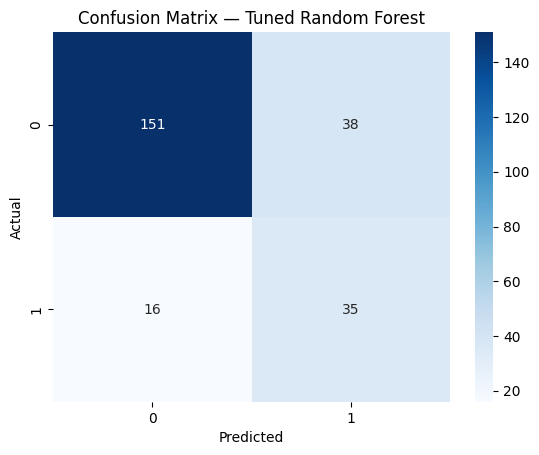

In [12]:
# Final classification evaluation
best_class_model = class_search.best_estimator_
class_pred = best_class_model.predict(X_test_c)
class_prob = best_class_model.predict_proba(X_test_c)[:, 1]

print("FINAL CLASSIFICATION MODEL: Tuned Random Forest")
print("Test accuracy:", round(accuracy_score(y_test_c, class_pred), 4))
print("Test precision:", round(precision_score(y_test_c, class_pred, zero_division=0), 4))
print("Test recall:", round(recall_score(y_test_c, class_pred, zero_division=0), 4))
print("Test F1:", round(f1_score(y_test_c, class_pred, zero_division=0), 4))
print("Test ROC-AUC:", round(roc_auc_score(y_test_c, class_prob), 4))
print("\nClassification report:")
print(classification_report(y_test_c, class_pred, zero_division=0))

cm = confusion_matrix(y_test_c, class_pred)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.title("Confusion Matrix — Tuned Random Forest")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

FINAL REGRESSION MODEL: Tuned Random Forest Regressor
Test MAE: 0.467
Test RMSE: 2.623
Test R²: 0.7241


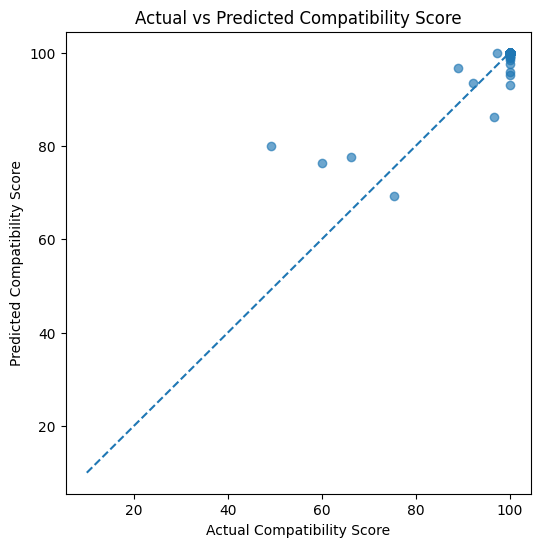

In [13]:
# Final regression evaluation
best_reg_model = reg_search.best_estimator_
reg_pred = best_reg_model.predict(X_test_r)
reg_pred = np.clip(reg_pred, 10, 100)

mae = mean_absolute_error(y_test_r, reg_pred)
rmse = np.sqrt(mean_squared_error(y_test_r, reg_pred))
r2 = r2_score(y_test_r, reg_pred)

print("FINAL REGRESSION MODEL: Tuned Random Forest Regressor")
print("Test MAE:", round(mae, 3))
print("Test RMSE:", round(rmse, 3))
print("Test R²:", round(r2, 4))

plt.figure(figsize=(6, 6))
plt.scatter(y_test_r, reg_pred, alpha=0.65)
plt.plot([10, 100], [10, 100], linestyle="--")
plt.xlabel("Actual Compatibility Score")
plt.ylabel("Predicted Compatibility Score")
plt.title("Actual vs Predicted Compatibility Score")
plt.show()

In [14]:
# Side-by-side CV comparison tables
print("Classification model comparison (cross-validation):")
display(classification_results_df.round(4))

print("Regression model comparison (cross-validation):")
display(regression_results_df.round(4))

print("Tuned classification model CV F1:", round(class_search.best_score_, 4))
print("Tuned regression model CV RMSE:", round(-reg_search.best_score_, 4))

Classification model comparison (cross-validation):


,Model,CV Accuracy Mean,CV Accuracy Std,CV F1 Mean,CV ROC-AUC Mean
0,Logistic Regression,0.8458,0.0112,0.5603,0.8689
1,AdaBoost,0.8250,0.0150,0.5096,0.8380
2,Decision Tree,0.7938,0.0222,0.4787,0.7451
3,Random Forest,0.8302,0.0182,0.4743,0.8394
4,KNN,0.8219,0.0227,0.4659,0.7967


Regression model comparison (cross-validation):


,Model,CV MAE Mean,CV RMSE Mean,CV R2 Mean
0,Random Forest Regressor,0.5523,2.7585,0.4435
1,AdaBoost Regressor,1.6486,3.2479,0.2526
2,KNN Regressor,0.5648,3.4162,0.2530
3,Linear Regression,1.5877,3.8449,0.0515
4,Decision Tree Regressor,0.6900,3.8824,0.0001


Tuned classification model CV F1: 0.5797
Tuned regression model CV RMSE: 2.8916
